# 06 · Inspect DECODE localisations

Inspect the current `decode_model/model_best.pt` on simulated frames with known emitters and on an experimental movie. Run from the repository root or the `localisation_workflow` folder. The settings cell controls the frame, crop, simulated density and detection threshold.

The simulated matching uses the lateral and axial tolerances from the saved run configuration. Real images have no ground truth here, so the overlays are a visual inspection rather than a measurement of accuracy.

In [5]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import tifffile
import torch
import torch.nn.functional as F

project = Path.cwd().resolve()
if not (project / 'decode_pure').is_dir():
    project = project.parent
if not (project / 'decode_pure').is_dir():
    raise FileNotFoundError('Open this notebook from the repository root or localisation_workflow.')
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from decode_pure import build_vae_simulator, load_sigma_munet, decode_nms_postprocess
from decode_pure.model import resolve_infer_device

model_dir = project / 'localisation_workflow' / 'decode_model'
weights = model_dir / 'model_best.pt'
params_path = model_dir / 'param_run_used.yaml'
movie_path = project / 'data' / 'low_density_examples' / 'RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3.tif'
device = resolve_infer_device('auto')  # Set to 'cpu' or 'cuda:0' if needed.
threshold = None  # None uses the saved run's threshold. Try e.g. 0.3.
seed = 2026
sim_densities = (12, 40, 80)
real_frame = 100  # Zero-based frame index
crop_size = 128
crop_row = None  # None centres the crop within the selected channel
crop_col = None
right_channel = True

torch.set_num_threads(4)
np.random.seed(seed)
torch.manual_seed(seed)
model, param = load_sigma_munet(params_path, weights, device=device)
threshold = float(param['PostProcessingParam']['raw_th']) if threshold is None else threshold
ch_in = int(param['HyperParameter']['channels_in'])
scale = param['Scaling']
camera = param['Camera']
print(f'Model: {weights.name}  |  device: {device}  |  input frames: {ch_in}  |  threshold: {threshold}')

Model: model_best.pt  |  device: mps  |  input frames: 3  |  threshold: 0.5


## Predict on an image window

The network takes frames in photon units and returns localisations in pixel coordinates. The first image axis is called x by DECODE, so plots use y on the horizontal axis and x on the vertical axis.

In [6]:
def predict(window_photons):
    frames = torch.as_tensor(window_photons, dtype=torch.float32, device=device)
    frames = (frames - scale['input_offset']) / scale['input_scale']
    h, w = frames.shape[-2:]
    arch = param['HyperParameter']['arch_param']
    stride = 2 ** max(arch['depth_shared'], arch['depth_union'])
    frames = F.pad(frames[None], (0, -w % stride, 0, -h % stride), mode='replicate')
    with torch.no_grad():
        output = model(frames)[:, :, :h, :w]
    detections = decode_nms_postprocess(
        output, raw_th=threshold, phot_max=scale['phot_max'], z_max=scale['z_max'],
        bg_max=scale['bg_max'], px_size=tuple(camera['px_size']),
        xy_origin=tuple(axis[0] + 0.5 for axis in param['TestSet']['frame_extent'][:2]),
    )
    return detections, output[0, 0].cpu().numpy()

def show_image(ax, image, title):
    lo, hi = np.percentile(image, (1, 99.7))
    ax.imshow(image, cmap='gray', vmin=lo, vmax=hi, interpolation='nearest')
    ax.set_title(title)
    ax.set_xlabel('Column (pixel)')
    ax.set_ylabel('Row (pixel)')

def show_predictions(ax, locs):
    ax.scatter(locs['y_px'], locs['x_px'], marker='+', s=48, linewidths=1.2,
               color='cyan', label=f"Predictions ({len(locs['x_px'])})")

def match_simulated(locs, xyz):
    # Follow DECODE's greedy nearest-pair matching and configured 3D gates.
    pred = np.column_stack((locs['x_nm'], locs['y_nm'], locs['z_nm']))
    truth = xyz.copy()
    truth[:, :2] *= np.asarray(camera['px_size'])
    if len(pred) == 0 or len(truth) == 0:
        return [], list(range(len(pred))), list(range(len(truth)))
    distances = np.linalg.norm(pred[:, None] - truth[None, :], axis=2)
    lateral = np.linalg.norm(pred[:, None, :2] - truth[None, :, :2], axis=2)
    axial = np.abs(pred[:, None, 2] - truth[None, :, 2])
    evaluation = param['Evaluation']
    for values, limit in ((lateral, evaluation.get('dist_lat')), (axial, evaluation.get('dist_ax')),
                          (distances, evaluation.get('dist_vol'))):
        if limit is not None:
            distances[values > limit] = np.inf
    matches = []
    while np.isfinite(distances).any():
        p, t = np.unravel_index(np.argmin(distances), distances.shape)
        matches.append((p, t))
        distances[p, :] = np.inf
        distances[:, t] = np.inf
    used_p = {p for p, _ in matches}
    used_t = {t for _, t in matches}
    return matches, [i for i in range(len(pred)) if i not in used_p], [i for i in range(len(truth)) if i not in used_t]

## Simulated data

Each panel uses a fresh temporal window from the frozen VAE background and bead-calibrated PSF. Green circles mark matched simulated emitters, orange circles mark missed emitters, cyan crosses mark matched predictions, and red crosses mark unmatched predictions. Emitters below the training photon-label threshold are excluded from matching and shown as faint grey dots. These few frames are for inspection, not a reliable aggregate performance estimate.

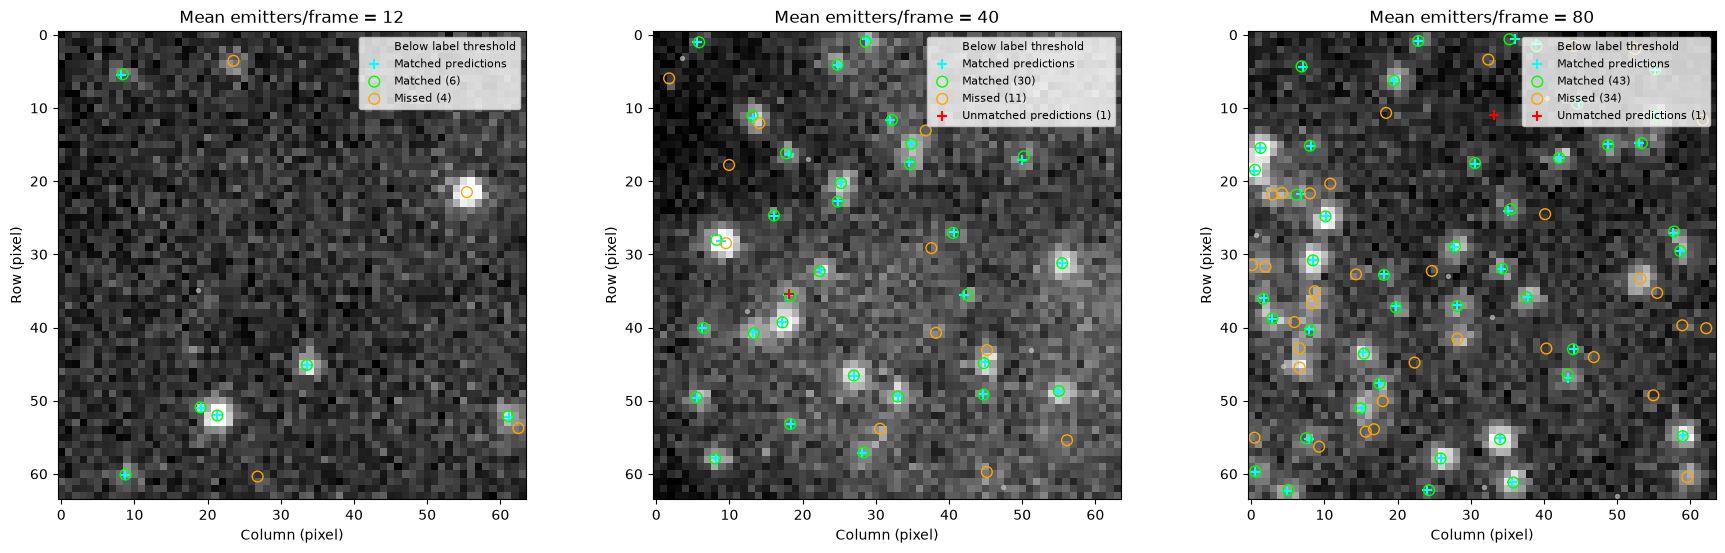

In [7]:
sim = build_vae_simulator(project_dir=project, param_rel=params_path,
                          frame_range=(0, ch_in - 1), device=device)
label_min = param['HyperParameter']['emitter_label_photon_min']
fig, axes = plt.subplots(1, len(sim_densities), figsize=(6 * len(sim_densities), 5.5), squeeze=False)
for ax, density in zip(axes[0], sim_densities):
    sim.em_sampler.emitter_av = density
    em, frames, backgrounds = sim.sample()
    centre = ch_in // 2
    locs, probability = predict(frames)
    em_c = em.get_subset_frame(centre).to('cpu')
    all_xyz = em_c.xyz_px.numpy()
    phot = em_c.phot.numpy()
    labelled = np.ones(len(phot), dtype=bool) if label_min is None else phot >= label_min
    xyz = all_xyz[labelled]
    matches, false_pos, false_neg = match_simulated(locs, xyz)
    show_image(ax, frames[centre].cpu().numpy(), f'Mean emitters/frame = {density}')
    if (~labelled).any():
        ax.scatter(all_xyz[~labelled, 1], all_xyz[~labelled, 0], s=8, color='lightgrey', alpha=.55, label='Below label threshold')
    if matches:
        truth_ix = [t for _, t in matches]
        pred_ix = [p for p, _ in matches]
        ax.scatter(locs['y_px'][pred_ix], locs['x_px'][pred_ix], marker='+', s=42, color='cyan', label='Matched predictions')
        ax.scatter(xyz[truth_ix, 1], xyz[truth_ix, 0], s=60, facecolors='none', edgecolors='lime', label=f'Matched ({len(matches)})')
    if false_neg:
        ax.scatter(xyz[false_neg, 1], xyz[false_neg, 0], s=60, facecolors='none', edgecolors='orange', label=f'Missed ({len(false_neg)})')
    if false_pos:
        ax.scatter(locs['y_px'][false_pos], locs['x_px'][false_pos], marker='+', s=55, color='red', label=f'Unmatched predictions ({len(false_pos)})')
    ax.legend(loc='upper right', fontsize=8)
fig.tight_layout()
plt.show()

## Experimental data

The selected TIFF pages are read on demand. The green box shows the crop in the full channel. Cyan crosses are model predictions on the cropped image. Camera ADU values are converted using the saved camera settings before inference.

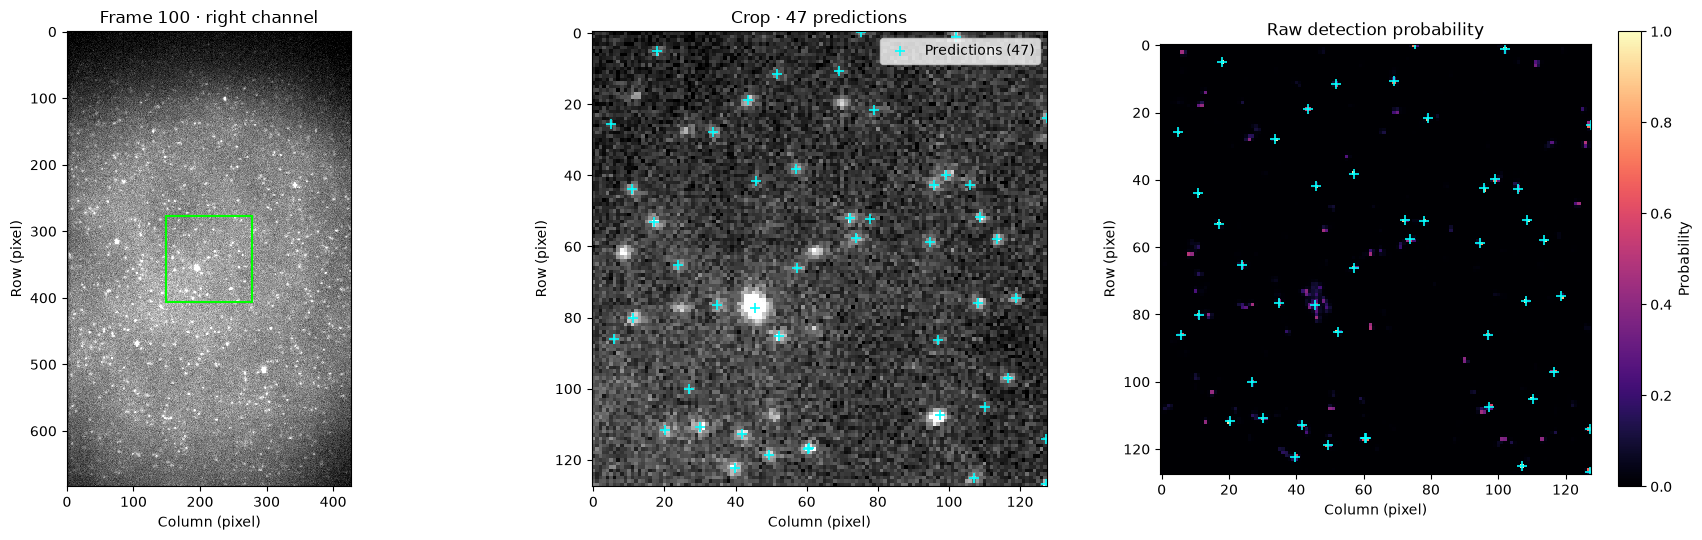

Crop origin in selected channel: row 278, column 150. Frame window: [99, 100, 101]
Predicted localisations: 47


In [8]:
with tifffile.TiffFile(movie_path) as tif:
    total_frames = len(tif.pages)
    if not 0 <= real_frame < total_frames:
        raise ValueError(f'real_frame must be between 0 and {total_frames - 1}')
    indices = np.clip(np.arange(ch_in) + real_frame - ch_in // 2, 0, total_frames - 1)
    stack = np.stack([tif.pages[int(i)].asarray() for i in indices]).astype(np.float32)
if right_channel:
    stack = stack[:, :, stack.shape[2] // 2:]
h, w = stack.shape[-2:]
if crop_size > min(h, w):
    raise ValueError(f'crop_size exceeds channel dimensions {(h, w)}')
row = (h - crop_size) // 2 if crop_row is None else crop_row
col = (w - crop_size) // 2 if crop_col is None else crop_col
if row < 0 or col < 0 or row + crop_size > h or col + crop_size > w:
    raise ValueError('The selected crop falls outside the channel.')
crop_adu = stack[:, row:row + crop_size, col:col + crop_size]
from decode_pure.simulator import CameraNoisePure
cam = CameraNoisePure(baseline=camera['baseline'], e_per_adu=camera['e_per_adu'],
                      qe=camera['qe'], read_sigma=camera['read_sigma'],
                      spur_noise=camera.get('spur_noise', 0), em_gain=camera.get('em_gain'),
                      convert2photons=camera.get('convert2photons', True))
crop_input = cam.backward(torch.from_numpy(crop_adu)).numpy() if cam.convert2photons else crop_adu
real_locs, real_probability = predict(crop_input)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
show_image(axes[0], stack[ch_in // 2], f'Frame {real_frame} · {"right" if right_channel else "full"} channel')
from matplotlib.patches import Rectangle
axes[0].add_patch(Rectangle((col - .5, row - .5), crop_size, crop_size, fill=False, edgecolor='lime', linewidth=1.5))
show_image(axes[1], crop_adu[ch_in // 2], f'Crop · {len(real_locs["x_px"])} predictions')
show_predictions(axes[1], real_locs)
axes[1].legend(loc='upper right')
im = axes[2].imshow(real_probability, cmap='magma', vmin=0, vmax=1)
show_predictions(axes[2], real_locs)
axes[2].set_title('Raw detection probability')
axes[2].set_xlabel('Column (pixel)')
axes[2].set_ylabel('Row (pixel)')
fig.colorbar(im, ax=axes[2], label='Probability')
fig.tight_layout()
plt.show()
print(f'Crop origin in selected channel: row {row}, column {col}. Frame window: {indices.tolist()}')
print(f'Predicted localisations: {len(real_locs["x_px"])}')

### Temporal input window

The three columns show the exact cropped frames supplied to the model. Both rows use the same contrast across time. The top row leaves the images unobscured. The bottom row repeats the **centre-frame predictions** on every frame so you can compare each predicted position over time. The model predicts the centre frame using all three images. Predictions may be influenced by neighbouring frames, but a marker over a visible spot does not establish that it is a real emitter.

At the start or end of a movie, the nearest frame is repeated for missing neighbours. A single-frame model displays one column.

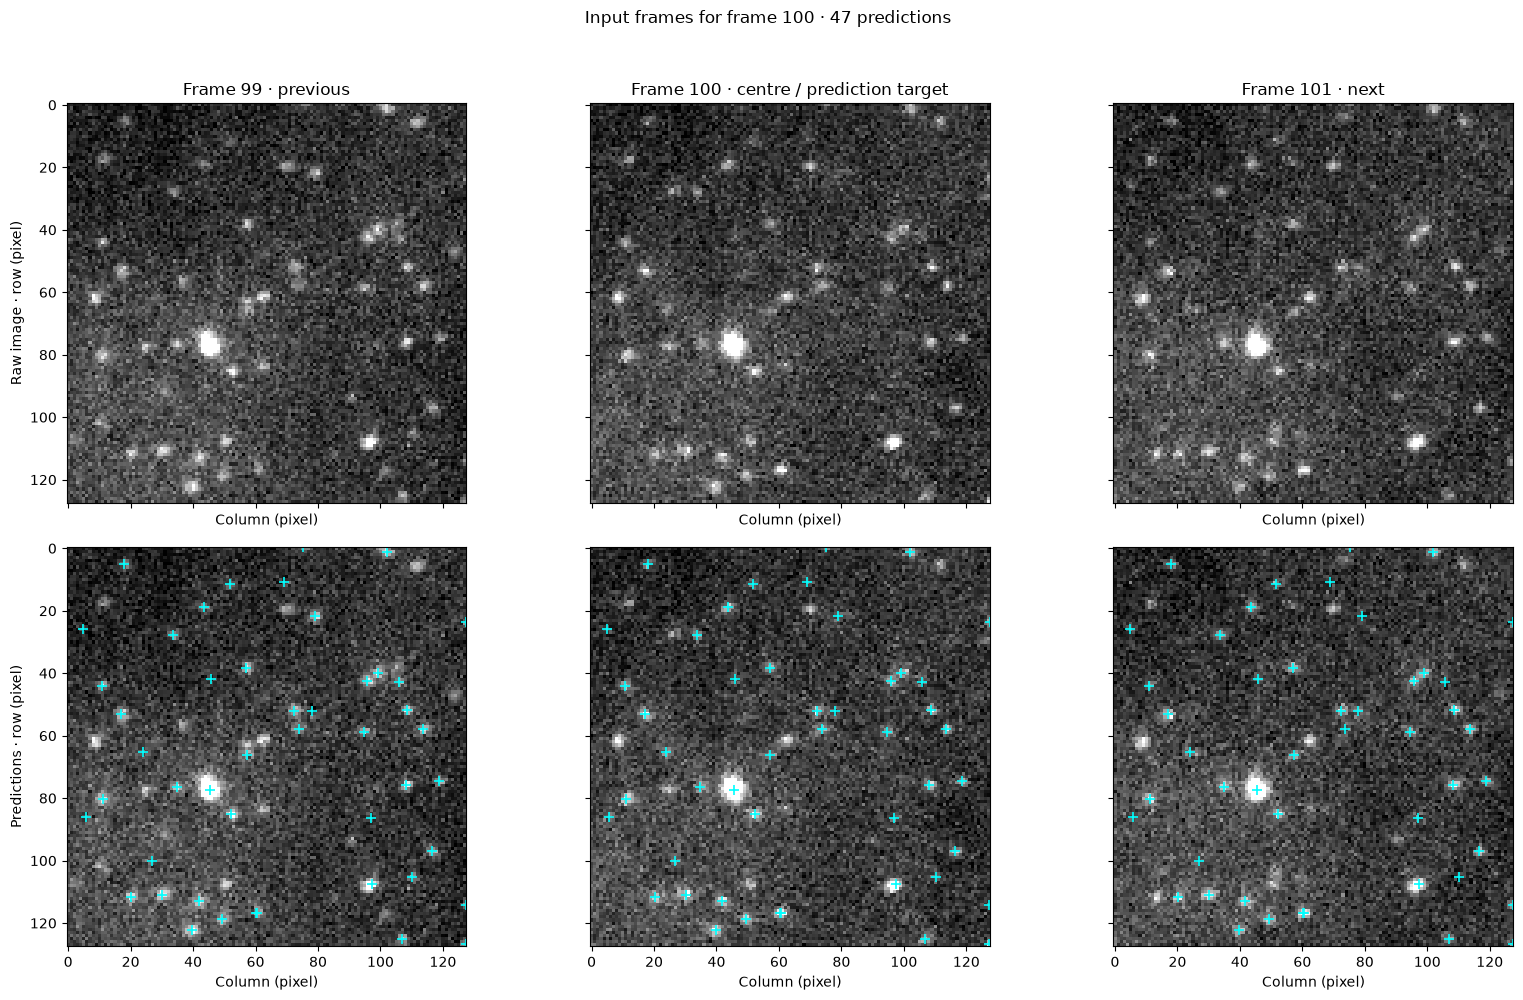

In [9]:
vmin, vmax = np.percentile(crop_adu, (1, 99.7))
fig, axes = plt.subplots(2, ch_in, figsize=(5.5 * ch_in, 10), squeeze=False,
                         sharex=True, sharey=True)
for i, frame_index in enumerate(indices):
    role = 'centre / prediction target' if i == ch_in // 2 else ('previous' if i < ch_in // 2 else 'next')
    for ax in axes[:, i]:
        ax.imshow(crop_adu[i], cmap='gray', vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_xlabel('Column (pixel)')
    axes[0, i].set_title(f'Frame {frame_index} · {role}')
    axes[1, i].scatter(real_locs['y_px'], real_locs['x_px'], marker='+', s=48,
                       linewidths=1.2, color='cyan')
axes[0, 0].set_ylabel('Raw image · row (pixel)')
axes[1, 0].set_ylabel('Predictions · row (pixel)')
fig.suptitle(f'Input frames for frame {real_frame} · {len(real_locs["x_px"])} predictions', y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

Predictions near the crop edges can change when the surrounding image changes, because the network uses spatial context. Change `real_frame`, `crop_row`, `crop_col`, or `threshold` in the settings cell and rerun the cells to inspect other regions.